# From macro paths to loss rates: scenario paths, satellites and a skewed-t severity

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic; notebooks 02 and 03 are not needed
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- say what a macro stress test is made of (a scenario path, satellite models and a capital engine) and which of those three this notebook covers;
- read the vintage and provider of each of the four scenarios of the case and see the engine refuse a path published after the observation date;
- transpose a published path onto the bank's jump-off: the Federal Reserve path as it is, the EBA annual path converted to quarters, and the NGFS deviation path added to its baseline, each recomputed with the engine's path functions and compared with the committed one;
- read a satellite regression, project it under a scenario by hand for one quarter and with `project_scenario` for twelve, and obtain the committed loss rates and the credit loss of each year;
- run the mechanics of two more scenario tools of the engine, the VAR conditional forecast and the Azzalini-Capitanio skewed-t fit of growth-at-risk, and say what each needs that the committed files do not hold.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.stress import paths, satellites, scenario_models
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the scenario side of **C18** (Banco Andino): four scenario variants and the satellites' models document.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** the four variant documents `data/derived/C18/baseline.json` and `fed-2026-severely-adverse.json` (Federal Reserve 2026, quarterly), `eba-2025-adverse.json` (EBA and ESRB 2025, annual, United States rows) and `ngfs-delayed-transition.json` (NGFS Phase V, NiGEM deviations from the baseline run, annual), and the models document `data/derived/C18/models-banco-andino.json` (the fitted satellites: coefficients, standard errors, sample windows). Each variant's `outputs.scenario` holds the published path, its transposition and its vintage; `outputs.satellites` the projected rates; `outputs.losses` the credit loss by year; `outputs.backcast` the realised rates 2020 to 2025.
- **What is not committed:** the Federal Reserve history 1985 to 2019 and the charge-off series the satellites were fitted on. Step 5 therefore **projects** the fitted satellites with the committed coefficients, but cannot **refit** them; the fit is `fit_satellite`, run by the pipeline on the raw files.
- **The adaptation, stated.** The paths are United States and euro-area paths; Banco Andino is Chilean and synthetic. Each path is transposed onto the bank's own jump-off value and the satellites are fitted on United States charge-off rates, so every loss rate of this notebook carries the label `us-calibrated-adaptation` in the documents. It teaches the machinery, not a forecast for Chile.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

VARIANTS = {"baseline": "baseline", "eba": "eba-2025-adverse", "fed": "fed-2026-severely-adverse", "ngfs": "ngfs-delayed-transition"}
docs = {key: read_json(f"C18/{name}.json") for key, name in VARIANTS.items()}
models = read_json("C18/models-banco-andino.json")["fit"]
AS_OF = docs["baseline"]["outputs"]["bank"]["as_of"]
print("variants:", list(VARIANTS.values()), "| observation date of the bank:", AS_OF)

derived folder found: True
variants: ['baseline', 'eba-2025-adverse', 'fed-2026-severely-adverse', 'ngfs-delayed-transition'] | observation date of the bank: 2026-08-31


## Method

### Step 1: the scenarios and their vintage

A macro stress test has three layers (dossier 05, H.1): a **scenario generator** for macro-financial paths over a two to three year horizon, **satellite models** that map the paths to risk parameters, and a **capital engine** that turns losses and revenues into capital ratios (notebook 05). This notebook covers the first two.

Every scenario is a published document with a date, its **vintage**. A scenario published after the date a model is observed would let the future into the validation, so the engine's `check_vintage` refuses a path whose vintage postdates the observation date and accepts equal dates. The next cell prints provider, document, vintage and the variables of each of the four scenarios, checks every vintage against the bank's observation date, and shows the refusal of a path dated one month after it.

In [3]:
# Print each scenario's provider, vintage and variables, check the vintage with the engine, and show a refusal
for key, doc in docs.items():
    scenario = doc["outputs"]["scenario"]
    paths.check_vintage(scenario["vintage_date"], AS_OF)
    print(f'{scenario["scenario_id"]:27s} provider {scenario["provider"]:9s} vintage {scenario["vintage_date"]} | variables: {[p["maps_to_regressor"] for p in scenario["paths"]]}')
print("all four vintages are on or before", AS_OF)
try:
    paths.check_vintage("2026-09-30", AS_OF)
except ValueError as err:
    print("a path dated 2026-09-30 is refused:", err)

baseline                    provider fed       vintage 2026-02-04 | variables: ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
eba-2025-adverse            provider eba-esrb  vintage 2025-02-26 | variables: ['real_gdp_growth', 'unemployment_rate', 'treasury_10y']
fed-2026-severely-adverse   provider fed       vintage 2026-02-04 | variables: ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
ngfs-delayed-transition     provider ngfs      vintage 2024-11-01 | variables: ['unemployment_rate', 'prime_rate', 'treasury_10y', 'real_gdp_growth']
all four vintages are on or before 2026-08-31
a path dated 2026-09-30 is refused: the vintage 2026-09-30 postdates the observation date 2026-08-31


### Step 2: the shape of a path on the bank's jump-off

The satellites run from the bank's last observed quarter, 2025 Q4, not from the date of the scenario's own jump-off. The engine therefore **transposes** a published path onto the target: the shape of the path, its change from its own jump-off, is kept and added to the bank's last observed value (decision Q6 of the case),

$$\tilde x_t = x^{\text{target}}_{0} + \left(x_t - x^{\text{source}}_{0}\right), \qquad t = 1, \dots, 12,$$

which `transpose_path(levels, source_jump_off, target_value, n)` implements. For the Federal Reserve scenarios the source jump-off is 2025 Q4 and the target is the same quarter, so the transposition changes nothing: the first test of the machinery is that it returns the published path. The next cell takes the unemployment rate of the severely adverse scenario, prints the published quarters, transposes with the engine and compares with the committed transposed path.

In [4]:
# Transpose the Federal Reserve severely adverse unemployment path with the engine and compare with the committed path
def path_of(key, regressor):
    return next(p for p in docs[key]["outputs"]["scenario"]["paths"] if p["maps_to_regressor"] == regressor)


unemployment = path_of("fed", "unemployment_rate")
levels = np.array([row["value"] for row in unemployment["levels"]])
jump, target = unemployment["transposition"]["source_jump_off"]["value"], unemployment["transposition"]["target"]["value"]
transposed = paths.transpose_path(levels, jump, target, 12)
committed_path = np.array([row["value"] for row in unemployment["transposed"]])
print("published quarters (13):", levels)
print("source jump-off:", jump, "| target:", target, "| transposed (12):", np.round(transposed, 2))
print("equal to the committed transposed path:", bool(np.allclose(transposed, committed_path)), "| first published quarter:", unemployment["source"][0]["date"])

published quarters (13): [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4  8. ]
source jump-off: 4.5 | target: 4.5 | transposed (12): [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4]
equal to the committed transposed path: True | first published quarter: 2026-03-31


### Step 3: the EBA path, from annual to quarterly

The EBA and ESRB publish annual levels for 2025, 2026 and 2027 only. The satellites are quarterly, so `annual_to_quarterly(year_end_levels, jump_off_level)` joins the year-end levels linearly from the jump-off level: quarter $k$ of a year is $\text{prev} + (\text{cur} - \text{prev})\,k/4$, and the fourth quarter is the year-end level itself. Whether the workbook's values are year averages or year-end values is UNVERIFIED in the research record, and the engine treats them as year-end levels. The jump-off of the EBA scenario is 2024 Q4 (the base year of the exercise), while the bank's is 2025 Q4, so the transposition now matters: the shape is kept and added to the bank's 2025 Q4 value. The next cell converts and transposes the unemployment and GDP-growth paths with the engine, prints the intermediate quarterly paths for unemployment, and compares with the committed transposition.

In [5]:
# Convert the EBA annual levels to quarters, transpose onto the bank's jump-off, and compare with the committed path
for regressor in ("unemployment_rate", "real_gdp_growth"):
    p = path_of("eba", regressor)
    year_end = np.array([row["value"] for row in p["levels"]])
    source_jump, target = p["transposition"]["source_jump_off"]["value"], p["transposition"]["target"]["value"]
    quarterly = paths.annual_to_quarterly(year_end, source_jump)
    moved = paths.transpose_path(quarterly, source_jump, target, 12)
    committed_moved = np.array([row["value"] for row in p["transposed"]])
    print(f"{regressor}: year-end levels {np.round(year_end, 3)} | source jump-off {source_jump:.3f} to target {target}")
    if regressor == "unemployment_rate":
        print("  quarterly (annual_to_quarterly):", np.round(quarterly, 3))
    print("  transposed:", np.round(moved, 3), "| equals the committed path:", bool(np.allclose(moved, committed_moved)))

unemployment_rate: year-end levels [ 8.914 10.046  8.647] | source jump-off 4.081 to target 4.5
  quarterly (annual_to_quarterly): [ 5.289  6.497  7.705  8.914  9.197  9.48   9.763 10.046  9.696  9.346
  8.997  8.647]
  transposed: [ 5.708  6.916  8.125  9.333  9.616  9.899 10.182 10.465 10.115  9.766
  9.416  9.066] | equals the committed path: True
real_gdp_growth: year-end levels [-5.055 -2.454  4.28 ] | source jump-off 2.765 to target 1.0
  transposed: [-0.955 -2.91  -4.865 -6.82  -6.169 -5.519 -4.869 -4.219 -2.535 -0.852
  0.832  2.515] | equals the committed path: True


### Step 4: the NGFS path, a deviation from a baseline run

The NGFS Phase V runs publish, for each scenario, the **deviation** from the Baseline run, so a scenario level is the baseline level plus the deviation (a percent difference for GDP): `level_from_deviation(baseline, deviation, kind)` with `kind` equal to `plus` or `percent`. The delayed-transition policy shock acts in **2031 to 2033** in the NGFS runs, so the case takes those three years and transposes them onto the bank's 2025 Q4 jump-off: the shape of the shock, not its calendar. The next cell rebuilds the unemployment and policy-rate levels from the baseline run and the deviation, converts to quarters with the 2030 jump-off, transposes onto the bank and compares with the committed path.

A published path ends at a horizon; the satellites may need more quarters. `revert_to_baseline(path, baseline_tail, n, reversion_quarters)` extends a path past its end by moving it linearly back to the baseline tail in `reversion_quarters` steps (a convention of the case, 12). The cell closes by extending the severely adverse unemployment path of step 2 to 24 quarters, which the committed 12-quarter horizon does not use.

In [6]:
# Rebuild the NGFS levels as baseline + deviation, convert, transpose, compare; then extend a path with the reversion rule
for regressor in ("unemployment_rate", "prime_rate"):
    p = path_of("ngfs", regressor)
    baseline_run = np.array([row["value"] for row in p["level_rule"]["baseline"]])
    deviation = np.array([row["value"] for row in p["source"]])
    rebuilt = paths.level_from_deviation(baseline_run, deviation, "plus")
    source_jump, target = p["transposition"]["source_jump_off"]["value"], p["transposition"]["target"]["value"]
    moved = paths.transpose_path(paths.annual_to_quarterly(rebuilt, source_jump), source_jump, target, 12)
    committed_moved = np.array([row["value"] for row in p["transposed"]])
    print(f"{regressor}: baseline run {np.round(baseline_run, 3)} + deviation {np.round(deviation, 3)} = {np.round(rebuilt, 3)}")
    print("  equals the committed levels:", bool(np.allclose(rebuilt, [row["value"] for row in p["levels"]])), "| transposed equals the committed path:", bool(np.allclose(moved, committed_moved)))
window = docs["ngfs"]["outputs"]["scenario"]["policy_shock_window"]
print("policy shock window:", window["start_year"], "to", window["end_year"])
baseline_tail = path_of("baseline", "unemployment_rate")["transposed"][-1]["value"]
extended = paths.revert_to_baseline(transposed, baseline_tail, 24, 12)
print("severely adverse unemployment extended to 24 quarters, reverting to", baseline_tail, ":", np.round(extended[10:], 2))

unemployment_rate: baseline run [4.442 4.494 4.537] + deviation [0.106 0.408 0.324] = [4.547 4.902 4.861]
  equals the committed levels: True | transposed equals the committed path: True
prime_rate: baseline run [3.25 3.25 3.25] + deviation [ 0.03  -0.57  -0.603] = [3.28  2.68  2.647]
  equals the committed levels: True | transposed equals the committed path: True
policy shock window: 2031 to 2033
severely adverse unemployment extended to 24 quarters, reverting to 4.3 : [8.7  8.4  8.06 7.72 7.38 7.03 6.69 6.35 6.01 5.67 5.32 4.98 4.64 4.3 ]


### Step 5: a satellite, by hand and with the engine

A satellite explains the loss rate $DR_t$ of a loan type by the macro variables, through a link $g$ (dossier 04, I.1 and dossier 05, H.1 layer 2):

$$g(DR_t) = \alpha + \sum_{k=1}^{p}\phi_k\, g(DR_{t-k}) + \sum_{j,\ell}\beta_{j\ell}\, X_{j,t-\ell} + \varepsilon_t.$$

With the **probit** link, $g = \Phi^{-1}$, the regression is a regression of the latent credit cycle of Vasicek's one-factor model on the macro variables, which is why the link is consistent with the portfolio models of topic 06. The segments whose rate is zero or negative in some quarters (net recoveries of real estate) use the identity link. In the case $p = 1$, the regressors are real GDP growth and the unemployment rate at lags 0 and 1, and each satellite is fitted by ordinary least squares on 1985 to 2019 (1991 to 2019 for the two real estate types).

The next cell reads the committed coefficients of the commercial-and-industrial satellite, takes the last realised rate (2025 Q4, from the back-cast block) and computes **the first projected quarter by hand**: link of the last rate, each term of the equation, the sum and the inverse link. It then calls `project_scenario` for all twelve quarters and for all five loan types under the Federal Reserve severely adverse scenario, and compares with the committed rates.

In [7]:
# The first projected quarter of the commercial-industrial satellite by hand, then project_scenario for all five loan types
fed_paths = {p["maps_to_regressor"]: p for p in docs["fed"]["outputs"]["scenario"]["paths"]}
X = np.column_stack([[row["value"] for row in fed_paths[name]["transposed"]] for name in ("real_gdp_growth", "unemployment_rate")])
jump_off = np.array([[fed_paths[name]["transposition"]["target"]["value"] for name in ("real_gdp_growth", "unemployment_rate")]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in docs["fed"]["outputs"]["backcast"]["per_loan_type"]}
committed_rates = {t["fed_loan_type"]: np.array([q["rate"] for q in t["quarters"]]) for t in docs["fed"]["outputs"]["satellites"]["fed_loan_types"]}


def satellite_fit(model):
    names = []
    for regressor in model["regressors"]:
        if regressor["name"] not in names:
            names.append(regressor["name"])
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"], n_obs=model["n_obs"],
        ar_order=model["ar_order"], regressor_names=tuple(names), lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in model["coefficients"]), estimates=tuple(c["estimate"] for c in model["coefficients"]),
        std_errors=tuple(c["std_error"] for c in model["coefficients"]), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


ci = next(m for m in models["satellites"] if m["fed_loan_type"] == "commercial-industrial")
coef = {c["name"]: c["estimate"] for c in ci["coefficients"]}
g0 = satellites.link("probit", np.array([last_rate["commercial-industrial"]]))[0]
terms = {"intercept": coef["intercept"], "ar_1 * g(last rate)": coef["ar_1"] * g0,
         "GDP growth, lag 0": coef["real_gdp_growth_lag0"] * X[0, 0], "GDP growth, lag 1": coef["real_gdp_growth_lag1"] * jump_off[0, 0],
         "unemployment, lag 0": coef["unemployment_rate_lag0"] * X[0, 1], "unemployment, lag 1": coef["unemployment_rate_lag1"] * jump_off[0, 1]}
print("last realised rate (2025 Q4):", last_rate["commercial-industrial"], "| probit link value:", round(float(g0), 4))
for name, value in terms.items():
    print(f"  {name:22s} {value:9.4f}")
by_hand = float(satellites.inverse_link("probit", np.array([sum(terms.values())]))[0])
print("sum of the terms:", round(sum(terms.values()), 4), "| inverse link (rate):", round(by_hand, 6), "| committed first quarter:", round(float(committed_rates["commercial-industrial"][0]), 6))
for model in models["satellites"]:
    fit = satellite_fit(model)
    projection = satellites.project_scenario(fit, satellites.link(fit.link, np.array([last_rate[model["fed_loan_type"]]])), jump_off, X)
    gap = float(np.max(np.abs(projection.rates - committed_rates[model["fed_loan_type"]])))
    print(f'{model["fed_loan_type"]:24s} link {fit.link:8s} n_obs {fit.n_obs:3d} R2 {fit.r_squared:.3f} | peak projected rate {projection.rates.max():.4f} | max gap to the committed rates {gap:.1e}')

last realised rate (2025 Q4): 0.005600000000000001 | probit link value: -2.5364
  intercept                -0.0269
  ar_1 * g(last rate)      -2.4236
  GDP growth, lag 0        -0.0038
  GDP growth, lag 1        -0.0074
  unemployment, lag 0       0.4169
  unemployment, lag 1      -0.3691
sum of the terms: -2.4138 | inverse link (rate): 0.007894 | committed first quarter: 0.007894
commercial-industrial    link probit   n_obs 139 R2 0.942 | peak projected rate 0.0180 | max gap to the committed rates 0.0e+00
commercial-real-estate   link identity n_obs 115 R2 0.959 | peak projected rate 0.0179 | max gap to the committed rates 0.0e+00
residential              link identity n_obs 115 R2 0.954 | peak projected rate 0.0114 | max gap to the committed rates 0.0e+00
credit-cards             link probit   n_obs 139 R2 0.926 | peak projected rate 0.0873 | max gap to the committed rates 0.0e+00
other-consumer           link probit   n_obs 139 R2 0.910 | peak projected rate 0.0206 | max gap to the 

The projection reproduces the committed rates to the last digit for all five loan types, so the committed path is exactly what the engine gives from the committed coefficients and path.

**From loan types to the bank's credit loss.** Banco Andino's book is in three classes, each mapped to Federal Reserve loan types with fixed weights (an adaptation of the case): commercial = 0.6 C&I + 0.4 commercial real estate, consumer = 0.5 credit cards + 0.5 other consumer, mortgage = residential. The credit loss of a year is the exposure of each class times the mean of the four quarterly rates of the year, summed over classes. The next cell rebuilds the class rates from the weights, the three annual credit losses, and compares them with the committed `losses` block.

In [8]:
# Class rates from the loan-type weights and the exposure, then the credit loss of each year against the committed block
annual_loss = np.zeros(3)
for klass in docs["fed"]["outputs"]["satellites"]["banco_andino_classes"]:
    class_rate = sum(w * committed_rates[t] for t, w in zip(klass["maps_from"], klass["weights"]))
    committed_class = np.array([q["rate"] for q in klass["quarters"]])
    yearly = class_rate.reshape(3, 4).mean(axis=1) * klass["exposure_clp_m"]
    annual_loss += yearly
    print(f'{klass["banco_andino_class"]:11s} weights {klass["weights"]} | exposure {klass["exposure_clp_m"]:12,.0f} | class rate equals the committed one: {bool(np.allclose(class_rate, committed_class))} | yearly loss {np.round(yearly, 0)}')
committed_loss = [row["credit"] for row in docs["fed"]["outputs"]["losses"]["scenario_losses"]]
print("credit loss by year here     :", np.round(annual_loss, 1))
print("credit loss by year committed:", np.round(committed_loss, 1))

commercial  weights [0.6, 0.4] | exposure    3,242,822 | class rate equals the committed one: True | yearly loss [40510. 54449. 31441.]
consumer    weights [0.5, 0.5] | exposure      683,660 | class rate equals the committed one: True | yearly loss [30755. 34862. 23885.]
mortgage    weights [1.0] | exposure    2,073,518 | class rate equals the committed one: True | yearly loss [15253. 22676. 15679.]
credit loss by year here     : [ 86518.6 111986.8  71005.1]
credit loss by year committed: [ 86518.6 111986.8  71005.1]


### Step 6: a VAR and a conditional forecast

The satellites map two chosen macro variables to loss rates. A **vector autoregression** models several variables together, $y_t = c + \sum_{l=1}^{p} A_l\, y_{t-l} + u_t$ (dossier 05, H.2), and a stress scenario is then a **conditional forecast**: the path of a subset of the variables is given, the others follow from the model, with the shocks of the free variables correlated with those of the conditioned ones. `fit_var(y, lags)` estimates it by OLS equation by equation and `var_conditional_forecast(fit, y_history, path, conditioned)` computes the conditional paths (the period-by-period form; the full-horizon form of Waggoner and Zha is UNVERIFIED against the paper).

The case does not bake a VAR, and the committed files hold no macro history to fit one on. What they do hold are real quarterly charge-off rates for 2020 to 2025 (the realised rates of the back-cast block), so the next cell runs the **mechanics** on those: a VAR(1) of the commercial-and-industrial rate and the credit-card rate (24 quarters, a short sample that only a demonstration can afford), conditioned on the credit-card rate following the satellite's projection under the severely adverse scenario. The output is what the C&I rate would do if card losses followed that path, to compare with the C&I satellite's own projection. It is an illustration of the tool, not a finding.

In [9]:
# A VAR(1) on the realised C&I and credit-card rates of 2020-2025, conditioned on the satellite path of the card rate
realised = {b["fed_loan_type"]: np.array([q["realised"] for q in b["quarters"]]) for b in docs["fed"]["outputs"]["backcast"]["per_loan_type"]}
y = np.column_stack([realised["commercial-industrial"], realised["credit-cards"]])
var_fit = scenario_models.fit_var(y, 1)
print("observations:", y.shape[0], "| intercept:", np.round(var_fit.intercept, 5))
print("A_1 =", np.round(var_fit.coefficients[0], 3).tolist(), "| eigenvalues of A_1:", np.round(np.linalg.eigvals(var_fit.coefficients[0]), 3))
card_path = committed_rates["credit-cards"].reshape(-1, 1)
conditional = scenario_models.var_conditional_forecast(var_fit, y[-1:], card_path, [1])
print("conditioned card rate (satellite):", np.round(card_path[:6, 0], 4))
print("C&I rate implied by the VAR      :", np.round(conditional[:6, 0], 4))
print("C&I rate of the satellite        :", np.round(committed_rates["commercial-industrial"][:6], 4))
print("the conditioned variable follows its path exactly:", bool(np.allclose(conditional[:, 1], card_path[:, 0])))

observations: 24 | intercept: [-0.00076 -0.00047]
A_1 = [[0.493, 0.081], [-1.922, 1.238]] | eigenvalues of A_1: [0.865+0.128j 0.865-0.128j]
conditioned card rate (satellite): [0.055  0.0688 0.0788 0.0855 0.0872 0.0873]
C&I rate implied by the VAR      : [0.0067 0.0082 0.0097 0.011  0.0119 0.0124]
C&I rate of the satellite        : [0.0079 0.0115 0.0148 0.0172 0.018  0.0179]
the conditioned variable follows its path exactly: True


### Step 7: growth-at-risk and the skewed-t density

**Growth-at-risk** (Adrian, Boyarchenko and Giannone 2019) builds a whole predictive distribution of GDP growth in two steps. Step 1 runs **quantile regressions** of average annualised growth on a constant, current growth and a financial-conditions index, one for each of the 5, 25, 75 and 95 percent quantiles. Step 2 fits the **Azzalini-Capitanio skewed-t** density

$$f(y;\mu,\sigma,\alpha,\nu) = \frac{2}{\sigma}\, t\!\left(\frac{y-\mu}{\sigma};\nu\right) T\!\left(\alpha\,\frac{y-\mu}{\sigma}\sqrt{\frac{\nu+1}{\nu+\left(\frac{y-\mu}{\sigma}\right)^2}};\ \nu+1\right)$$

to the four estimated quantiles by least squares, where $t$ and $T$ are the Student $t$ density and distribution function and $\alpha$ the skewness ($\alpha = 0$ is the Student t). Lower quantiles move strongly with financial conditions while the upper ones are stable, which makes the fitted density a **severity calibrator** for scenarios.

The engine has both steps. `gar_quantile_regressions` needs `statsmodels` (the optional `stress` extra of the engine) and a financial-conditions series; **neither is in the notebook environment or in the committed files**, so step 1 is not run here. Step 2, `fit_skewed_t_to_quantiles`, needs only four quantiles, and the next cell tests it two ways. First, the density at $\alpha = 0$ must equal the Student t and integrate to 1. Second, a known-truth fit: the quantiles of a normal distribution with the standard deviation of real GDP growth over 1985 to 2019 (the committed `factor_space`) should return $\alpha \approx 0$ and a large $\nu$; then a lower-tail-heavy set of quantiles, the shape growth-at-risk finds in stressed conditions (illustrative multiples of that standard deviation), should return a negative $\alpha$.

In [10]:
# Check the skewed-t density against the Student t, then fit it to known-truth and to lower-tail-heavy quantiles
grid = np.linspace(-12, 12, 4001)
print("alpha = 0 equals the Student t density:", bool(np.allclose(scenario_models.skewed_t_pdf(grid, 0.0, 1.0, 0.0, 5.0), stats.t.pdf(grid, 5))))
print("area under the alpha = -3 density over [-12, 12]:", round(float(np.trapezoid(scenario_models.skewed_t_pdf(grid, 0.0, 1.0, -3.0, 5.0), grid)), 4))
sd_growth = models["factor_space"]["factors"][0]["sd"]
taus = np.array([0.05, 0.25, 0.75, 0.95])
truth = scenario_models.fit_skewed_t_to_quantiles(stats.norm.ppf(taus) * sd_growth)
print(f"normal quantiles with sd {sd_growth:.3f}: mu {truth.mu:.2e}, sigma {truth.sigma:.3f}, alpha {truth.alpha:.2e}, nu {truth.nu:.0f}, distance {truth.distance:.1e}")
heavy = scenario_models.fit_skewed_t_to_quantiles(np.array([-2.4, -0.9, 0.6, 1.5]) * sd_growth)
print(f"lower-tail-heavy quantiles: mu {heavy.mu:.3f}, sigma {heavy.sigma:.3f}, alpha {heavy.alpha:.3f}, nu {heavy.nu:.2f}, distance {heavy.distance:.1e}")
print("with four quantiles and four parameters a fit is exact, so the distance is about 0 whenever the optimiser converges")

alpha = 0 equals the Student t density: True
area under the alpha = -3 density over [-12, 12]: 0.9999
normal quantiles with sd 2.281: mu -2.57e-07, sigma 2.279, alpha 1.41e-07, nu 1000, distance 1.3e-06
lower-tail-heavy quantiles: mu 2.063, sigma 3.393, alpha -1.833, nu 10.20, distance 1.6e-23
with four quantiles and four parameters a fit is exact, so the distance is about 0 whenever the optimiser converges


## Results

The figure shows the four scenarios' unemployment paths after transposition (left) and the credit-card loss rate that the satellite projects under each of them (right). The paths differ in shape and severity, and the satellite converts the difference into a loss rate with a lag and a ceiling of its own.

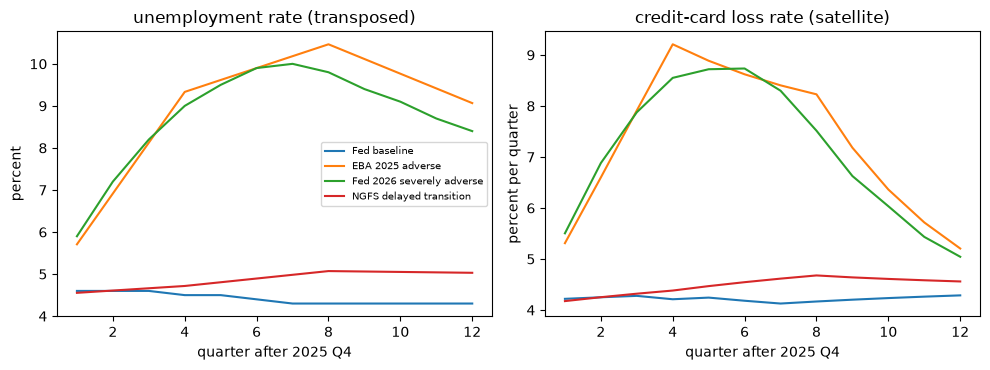

peak card loss rate by scenario: {'Fed baseline': 4.29, 'EBA 2025 adverse': 9.21, 'Fed 2026 severely adverse': 8.73, 'NGFS delayed transition': 4.68}


In [11]:
# Draw the transposed unemployment paths and the credit-card rate each scenario implies through the satellite
cards = next(m for m in models["satellites"] if m["fed_loan_type"] == "credit-cards")
card_fit = satellite_fit(cards)
card_last = satellites.link("probit", np.array([last_rate["credit-cards"]]))
LABEL = {"baseline": "Fed baseline", "eba": "EBA 2025 adverse", "fed": "Fed 2026 severely adverse", "ngfs": "NGFS delayed transition"}
quarters = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
implied = {}
for key in docs:
    p_u, p_g = path_of(key, "unemployment_rate"), path_of(key, "real_gdp_growth")
    unemployment_path = np.array([row["value"] for row in p_u["transposed"]])
    x_path = np.column_stack([[row["value"] for row in p_g["transposed"]], unemployment_path])
    start = np.array([[p_g["transposition"]["target"]["value"], p_u["transposition"]["target"]["value"]]])
    implied[key] = satellites.project_scenario(card_fit, card_last, start, x_path).rates
    axes[0].plot(quarters, unemployment_path, label=LABEL[key])
    axes[1].plot(quarters, implied[key] * 100, label=LABEL[key])
axes[0].set_title("unemployment rate (transposed)")
axes[0].set_ylabel("percent")
axes[1].set_title("credit-card loss rate (satellite)")
axes[1].set_ylabel("percent per quarter")
for ax in axes:
    ax.set_xlabel("quarter after 2025 Q4")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("peak card loss rate by scenario:", {LABEL[k]: round(float(v.max()) * 100, 2) for k, v in implied.items()})

- **Every vintage is on or before the observation date, 2026-08-31** (Federal Reserve 2026-02-04, EBA 2025-02-26, NGFS 2024-11-01), and the engine refuses a path dated 2026-09-30.
- **The engine reproduces the four committed transpositions.** The Federal Reserve path is unchanged by construction (unemployment from 5.9 percent in the first quarter to a peak of 10.0 in the seventh). The EBA annual levels become 12 quarters and move up by 0.42 points of unemployment and down by 1.76 points of GDP growth to the bank's jump-off (peaks of 10.47 percent unemployment and a growth trough of -6.82). The NGFS levels are baseline plus deviation (unemployment 4.547, 4.902 and 4.861 percent; the policy rate falls by 0.57 to 0.60 points) for the 2031 to 2033 window. Each equals the committed path.
- **The satellite is a plain equation.** For commercial and industrial loans the first projected quarter is the sum of six terms (the autoregressive term, -2.42, dominates; unemployment adds 0.42 and its lag takes back 0.37) and gives a rate of 0.007894, the committed value. All five satellites reproduce the committed twelve quarters with a maximum gap of 0, with $R^2$ between 0.910 and 0.959 on 115 to 139 observations; the highest projected quarterly rate is 8.73 percent for credit cards and 1.14 percent for residential mortgages.
- **The bank's credit loss follows exactly:** CLP 86,518.6, 111,986.8 and 71,005.1 million in the three years of the severely adverse scenario, equal to the committed block, with the class rates equal to the weighted loan-type rates.
- **The VAR conditional forecast runs but is not the satellite.** Conditioned on the card rate following the satellite path, the C&I rate it implies peaks at 1.24 percent against 1.80 percent in the C&I satellite: two models of the same quantity from different samples (24 quarters against 139) disagree, which is a reason to keep a challenger beside the champion, not a result about either.
- **The skewed-t fit recovers a known truth** (normal quantiles with the 2.281 standard deviation of GDP growth return $\alpha \approx 10^{-7}$ and $\sigma = 2.279$, with $\nu$ at the search ceiling of 1000, a normal in the limit) and returns $\alpha = -1.83$, $\nu = 10.2$ for lower-tail-heavy quantiles.
- **The scenarios rank the card loss rate as the paths suggest.** The quarterly peak is 4.29 percent in the Federal Reserve baseline, 4.68 percent under NGFS, 8.73 percent under the Federal Reserve severely adverse and 9.21 percent under the EBA adverse, whose transposed GDP trough (-6.82) and unemployment peak (10.47) are deeper than the Federal Reserve's.

What this notebook does not show: the satellites were projected, not refitted (the 1985 to 2019 history is not committed); the first quantile-regression step of growth-at-risk was not run; and none of these rates is a forecast for Chile, because paths and coefficients are United States ones transposed onto a synthetic bank.

## Summary

- A macro stress test has three layers; this notebook covered the scenario paths and the satellites, and notebook 05 covers the capital engine.
- A path published after the observation date is refused by `check_vintage`; every committed vintage is on or before it.
- A published path is moved onto the bank's jump-off by keeping its shape: as it is for the Federal Reserve, after an annual-to-quarterly join for the EBA, and as a baseline plus a deviation for the NGFS. The engine reproduces each committed path.
- A probit satellite is a regression of the latent credit cycle on macro variables; with the committed coefficients the engine reproduces the committed loss rates and the bank's credit loss by year exactly, but the satellites cannot be refitted from the committed files.
- The VAR conditional forecast and the skewed-t fit of growth-at-risk are engine tools the case does not bake; their mechanics were run on committed data and known truth, and growth-at-risk's quantile regressions need `statsmodels` and a financial-conditions series that this environment does not have.

**What to try next.** Swap the scenario of step 5 for the EBA one and compare the peak loss rates of the five loan types. Then continue with notebook 05, which takes the losses and builds the capital plan.

## References

- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- NGFS (2024), Climate scenarios, Phase V (launch). https://www.ngfs.net/en/news/ngfs-scenarios-phase-v-launch-event
- NGFS Phase V scenarios, IIASA Scenario Explorer (the NiGEM runs the case reads). https://data.ene.iiasa.ac.at/ngfs
- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Board of Governors of the Federal Reserve System (2026), 2026 supervisory severely adverse scenario, domestic (the quarterly macro path file). https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_Severely_Adverse_Domestic.csv
- Dossiers 04 (I.1, the satellite and the Vasicek link) and 05 (H.1 and H.2, the three layers, the VAR and growth-at-risk) of the persisted Contraste research, as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the path, satellite and scenario-model functions).